# AE4 · Métricas y visualización de la supervivencia en el Titanic

Proyecto Integrado III · Analítica de Datos · Santiago Andrés Valencia Duque

Este notebook calcula las métricas de las cinco preguntas de negocio a partir del dataset preparado en AE3 (`titanic_preparado.csv`), comprueba que coincidan con las tablas exportadas por el notebook de AE3, genera las figuras del documento y exporta las tablas complementarias. La aplicación de Streamlit (`streamlit_app.py`) usa el mismo módulo `src/metricas.py`, por lo que sus cifras son las mismas que se ven aquí.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'streamlit_app.py').exists())
CARPETA = RAIZ / 'AE4 Proyecto integrador - Métricas y Visualización'
sys.path.insert(0, str(CARPETA / 'src'))
import metricas as m
import graficos as g

resultado = m.calcular_todo(RAIZ)
datos = resultado['datos']
print(f'Dataset preparado: {datos.shape[0]} filas y {datos.shape[1]} columnas')
datos.head()

Dataset preparado: 891 filas y 9 columnas


,sobrevivio,clase_pasajero,sexo,edad,tarifa,ciudad_embarque,estado_supervivencia,clase,grupo_edad
0,0,3,Hombre,22.0,7.2500,Southampton,No sobrevivió,Tercera,18 a 29
1,1,1,Mujer,38.0,71.2833,Cherbourg,Sobrevivió,Primera,30 a 44
2,1,3,Mujer,26.0,7.9250,Southampton,Sobrevivió,Tercera,18 a 29
3,1,1,Mujer,35.0,53.1000,Southampton,Sobrevivió,Primera,30 a 44
4,0,3,Hombre,35.0,8.0500,Southampton,No sobrevivió,Tercera,30 a 44


## Definición de las métricas

| Métrica | Cálculo | Unidad |
|---|---|---|
| Pasajeros | Número de registros del grupo | Personas |
| Sobrevivientes | Suma de `sobrevivio` (1 = sobrevivió) | Personas |
| No sobrevivientes | Pasajeros − sobrevivientes | Personas |
| Tasa de supervivencia | Sobrevivientes / pasajeros × 100 | % |
| Participación | Pasajeros del grupo / 891 × 100 | % |
| Brecha | Diferencia entre dos tasas | Puntos porcentuales (p. p.) |
| Tarifa total (complemento) | Suma de `tarifa` por clase; ingreso registrado, no rentabilidad | Moneda no indicada |

## Verificación contra los resultados de AE3

In [2]:
verificacion = resultado['verificacion']
assert verificacion['coincide_con_ae3'].all(), 'Las cifras no coinciden con AE3'
verificacion

,tabla,grupos,pasajeros,sobrevivientes,coincide_con_ae3
0,pregunta_1_supervivencia_total,1,891,342,True
1,pregunta_2_supervivencia_por_clase,3,891,342,True
2,pregunta_3_supervivencia_por_sexo,2,891,342,True
3,pregunta_4_supervivencia_por_grupo_edad,7,891,342,True
4,pregunta_5_supervivencia_por_puerto,4,891,342,True


## Tablas por pregunta

In [3]:
for nombre, tabla in resultado['tablas'].items():
    print(nombre)
    display(tabla)

pregunta_1_supervivencia_total


,grupo,pasajeros,sobrevivientes,no_sobrevivientes,tasa_supervivencia_pct,participacion_pasajeros_pct
0,Total,891,342,549,38.38,100.0


pregunta_2_supervivencia_por_clase


,clase,pasajeros,sobrevivientes,no_sobrevivientes,tasa_supervivencia_pct,participacion_pasajeros_pct
0,Primera,216,136,80,62.96,24.24
1,Segunda,184,87,97,47.28,20.65
2,Tercera,491,119,372,24.24,55.11


pregunta_3_supervivencia_por_sexo


,sexo,pasajeros,sobrevivientes,no_sobrevivientes,tasa_supervivencia_pct,participacion_pasajeros_pct
0,Mujer,314,233,81,74.20,35.24
1,Hombre,577,109,468,18.89,64.76


pregunta_4_supervivencia_por_grupo_edad


,grupo_edad,pasajeros,sobrevivientes,no_sobrevivientes,tasa_supervivencia_pct,participacion_pasajeros_pct
0,0 a 12,69,40,29,57.97,7.74
1,13 a 17,44,21,23,47.73,4.94
2,18 a 29,271,95,176,35.06,30.42
3,30 a 44,215,91,124,42.33,24.13
4,45 a 59,89,36,53,40.45,9.99
5,60 o más,26,7,19,26.92,2.92
6,Edad no registrada,177,52,125,29.38,19.87


pregunta_5_supervivencia_por_puerto


,puerto_embarque,pasajeros,sobrevivientes,no_sobrevivientes,tasa_supervivencia_pct,participacion_pasajeros_pct
0,Cherbourg,168,93,75,55.36,18.86
1,Queenstown,77,30,47,38.96,8.64
2,Southampton,644,217,427,33.70,72.28
3,No registrado,2,2,0,100.00,0.22


## Tablas complementarias

Lectura conjunta de clase y sexo, y tarifas por clase.

In [4]:
display(resultado['clase_sexo'])
display(resultado['tarifas'])
print('Exportadas en:', m.exportar(resultado).relative_to(RAIZ))

,clase,sexo,pasajeros,sobrevivientes,tasa_supervivencia_pct
0,Primera,Mujer,94,91,96.81
1,Primera,Hombre,122,45,36.89
2,Segunda,Mujer,76,70,92.11
3,Segunda,Hombre,108,17,15.74
4,Tercera,Mujer,144,72,50.00
5,Tercera,Hombre,347,47,13.54


,clase,pasajeros,tarifa_total,tarifa_media,tarifa_mediana,pasajes_tarifa_cero,participacion_tarifa_pct,participacion_pasajeros_pct
0,Primera,216,18177.41,84.15,60.29,5,63.35,24.24
1,Segunda,184,3801.84,20.66,14.25,6,13.25,20.65
2,Tercera,491,6714.70,13.68,8.05,4,23.40,55.11


Exportadas en: AE4 Proyecto integrador - Métricas y Visualización/resultados


## Figuras

Cada figura incluye título, ejes con unidades y la fuente. Las mismas gráficas, en versión interactiva, están en la aplicación de Streamlit.

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_p1_supervivencia_total.png


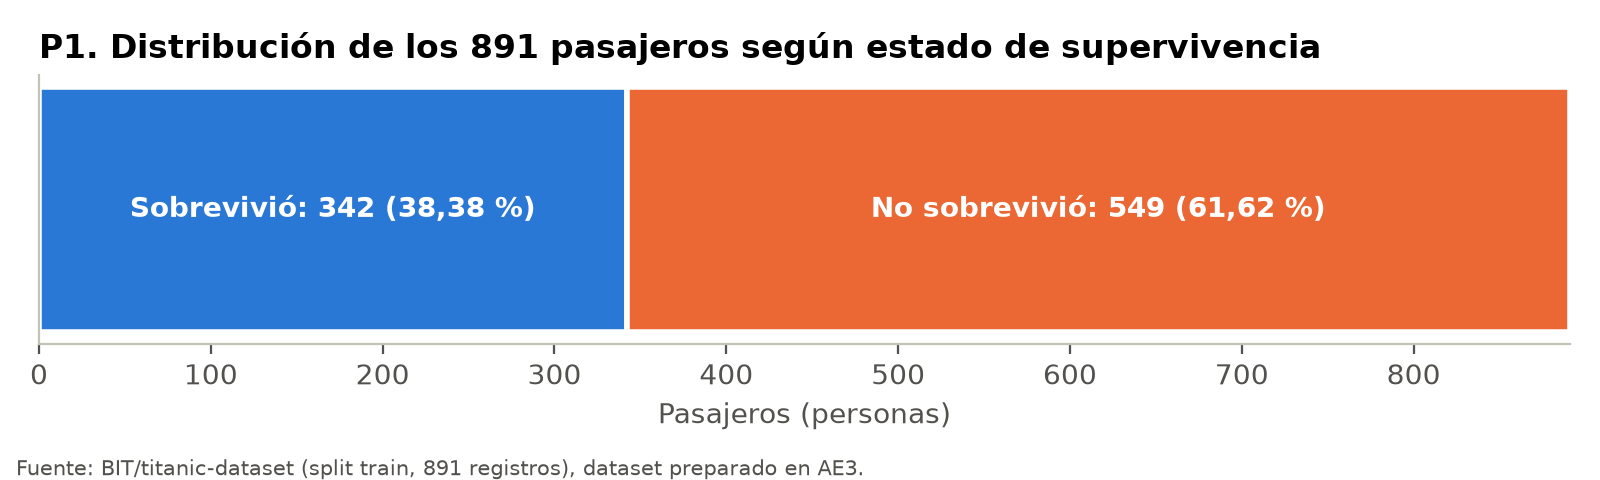

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_p2_clase.png


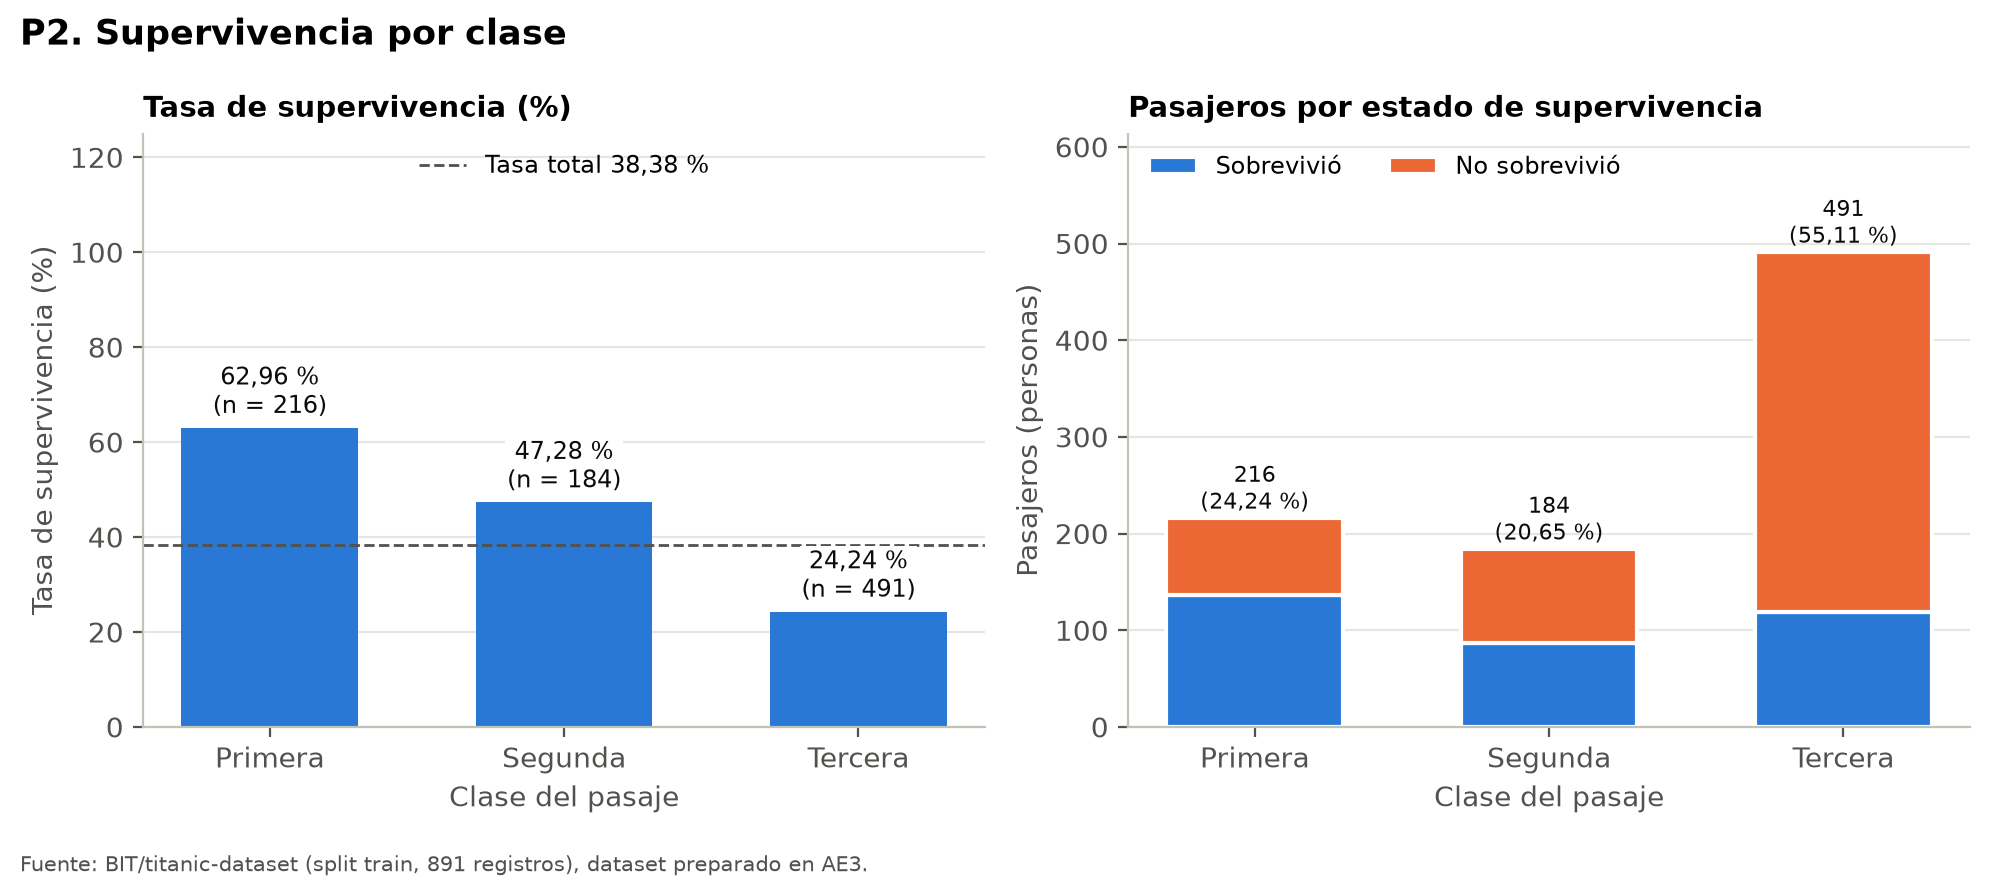

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_p3_sexo.png


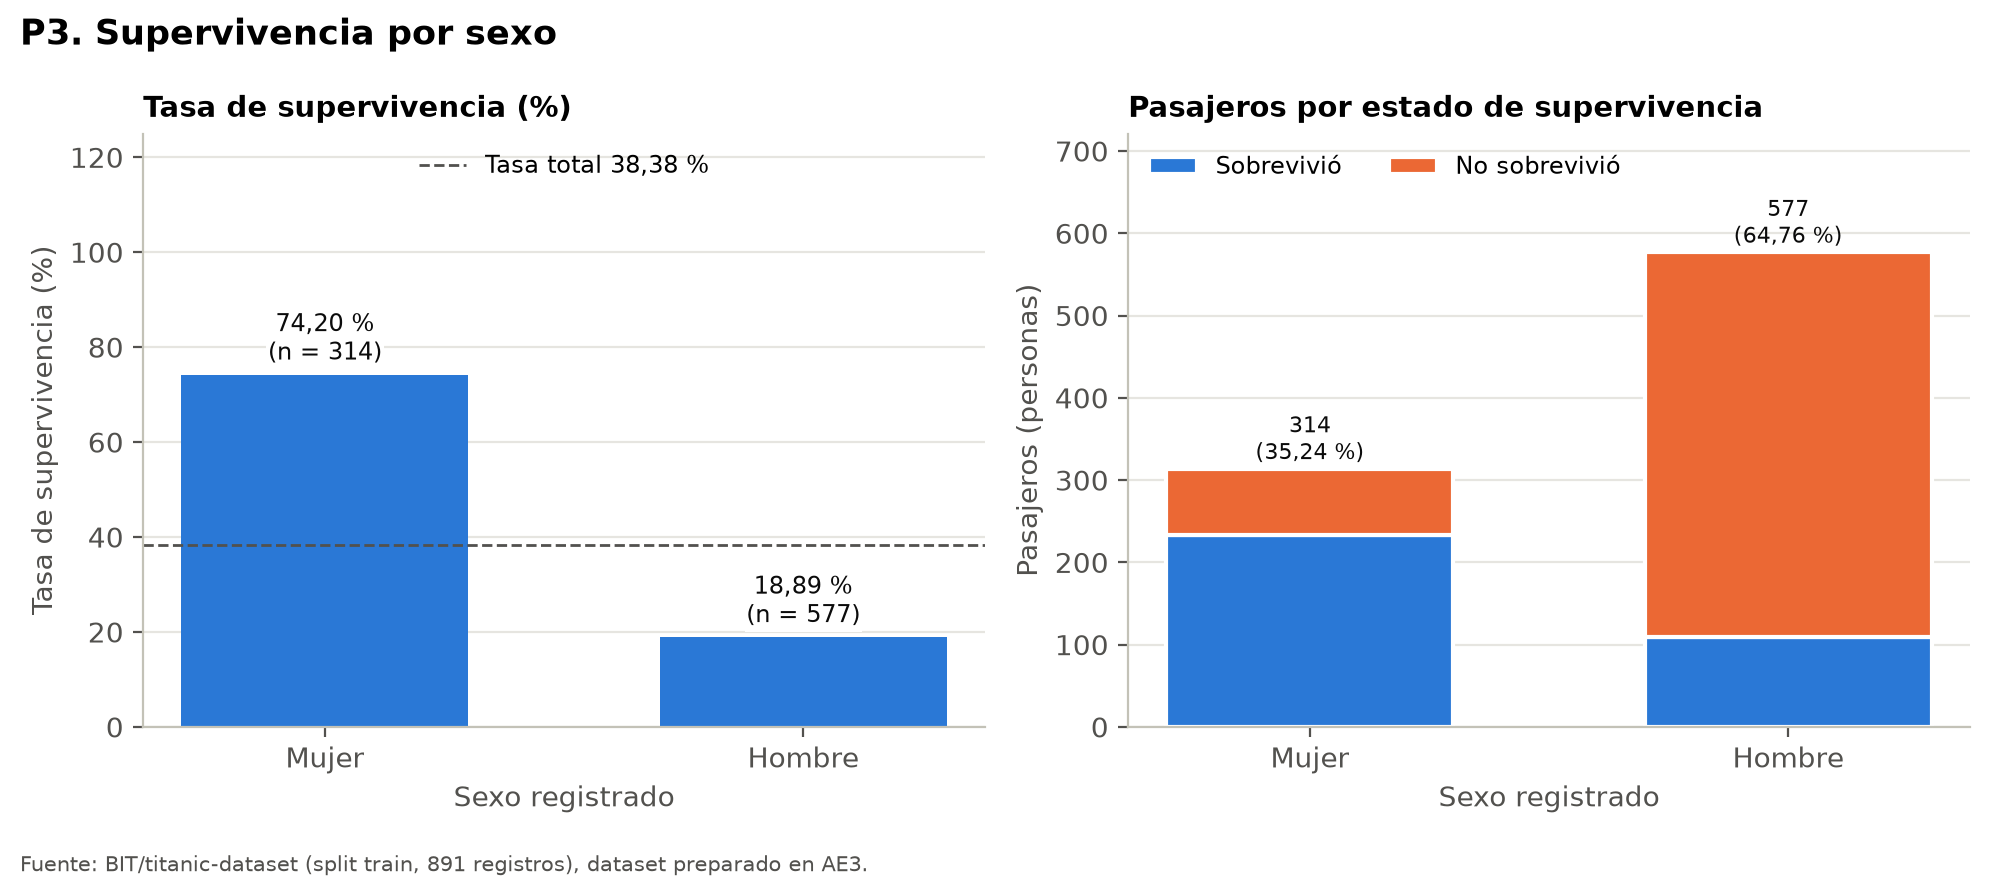

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_p4_grupo_edad.png


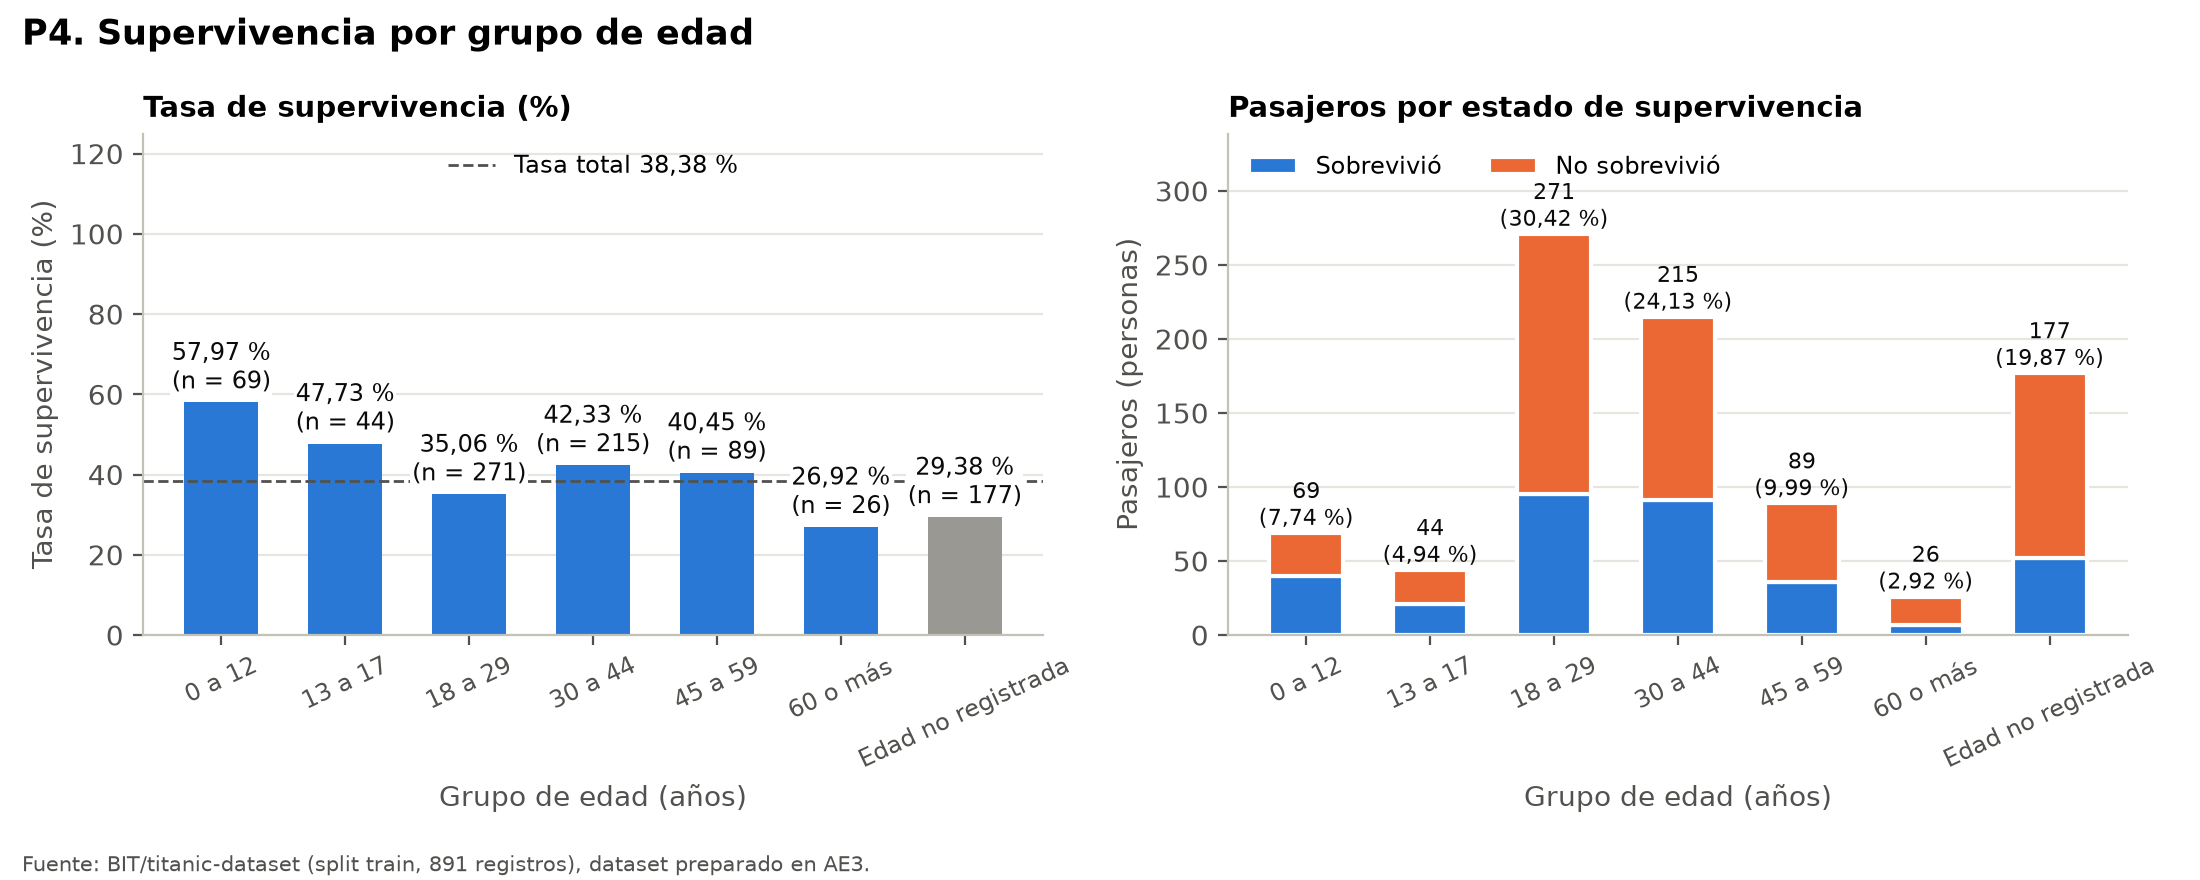

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_p5_puerto_embarque.png


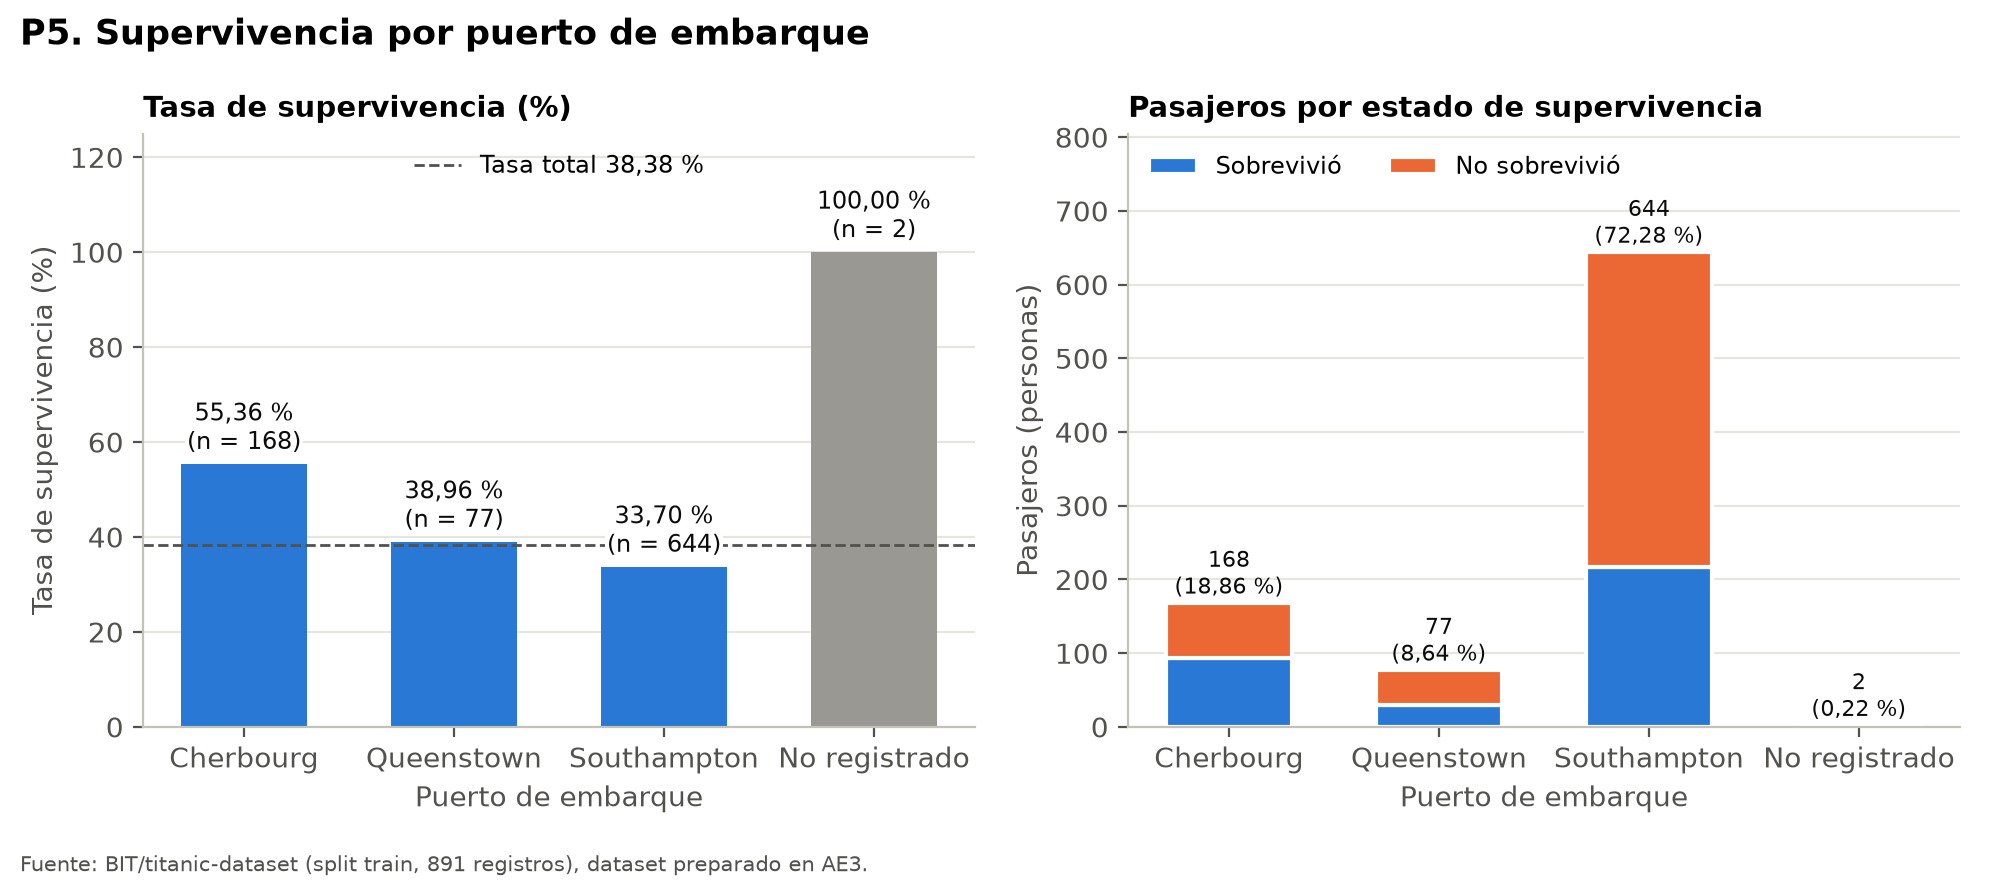

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_complemento_clase_sexo.png


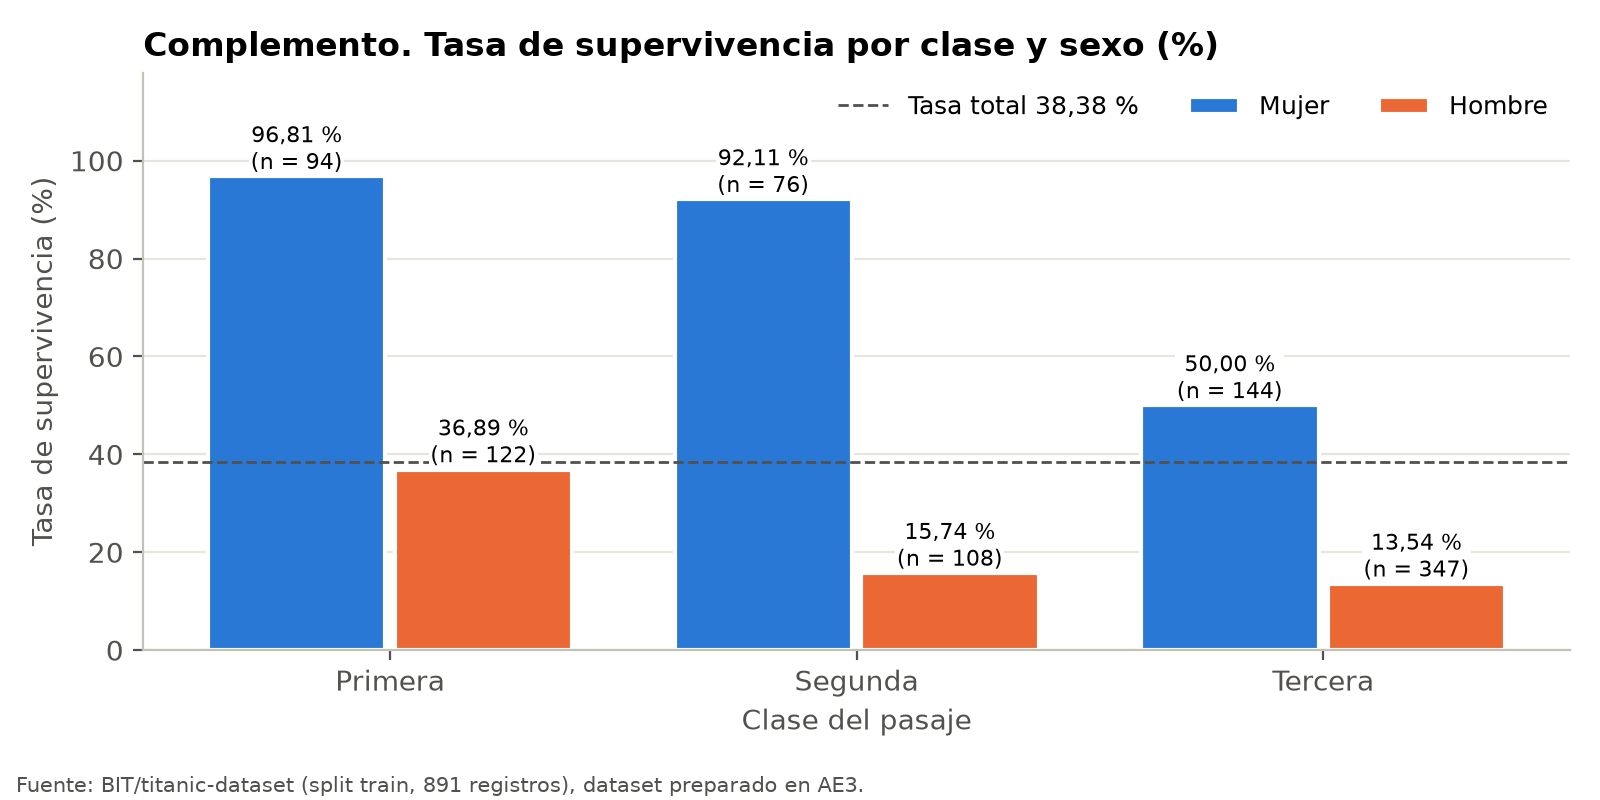

AE4 Proyecto integrador - Métricas y Visualización/figuras/fig_complemento_tarifas.png


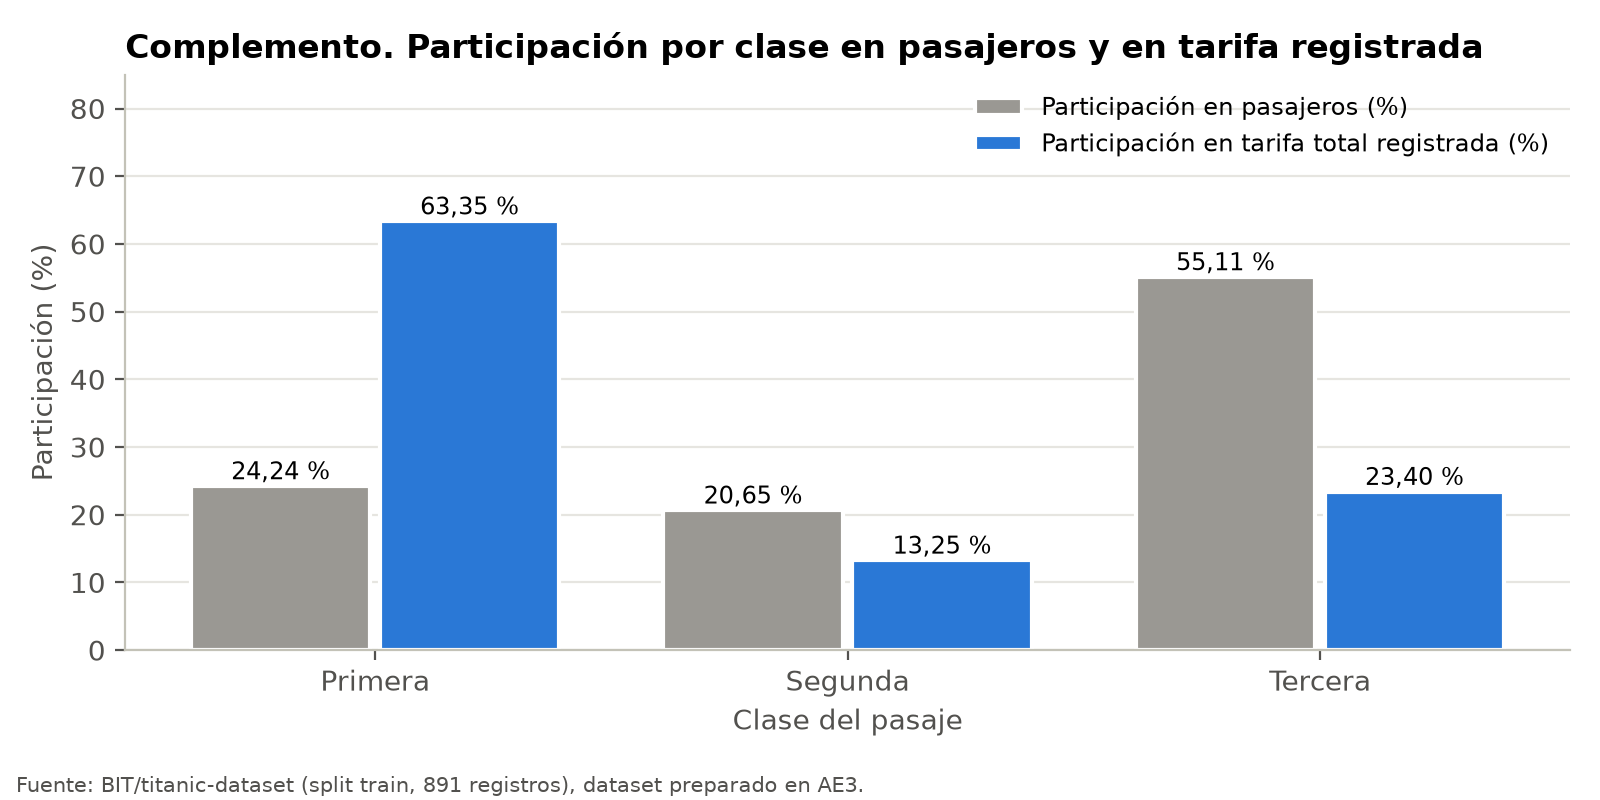

In [5]:
rutas = g.generar_figuras(resultado, CARPETA / 'figuras')
for clave, ruta in rutas.items():
    print(ruta.relative_to(RAIZ))
    display(Image(filename=str(ruta), width=760))

## Hallazgos principales

- Tasa total: 38,38 % (342 de 891). Es la referencia para comparar los grupos.
- Clase: Primera 62,96 %, Segunda 47,28 %, Tercera 24,24 %.
- Sexo: mujeres 74,20 % frente a hombres 18,89 % (brecha de 55,31 p. p.), que se mantiene en las tres clases.
- Edad: 0 a 12 años 57,97 %; 60 o más 26,92 %; 177 edades no registradas.
- Puerto: Cherbourg 55,36 %, Queenstown 38,96 %, Southampton 33,70 %.
- Tarifas: la primera clase reúne el 24,24 % de los pasajeros y el 63,35 % de la tarifa registrada (ingreso, no rentabilidad).

El análisis es descriptivo: muestra asociaciones en los registros, no causas.